# Two sensors in, four outputs out

This notebook gives one model two inputs (Sentinel-2 optical and Sentinel-1 radar) and four
outputs: a water mask, water-body edges, distance to the nearest edge and the share of the chip
under water. It uses the same flood dataset as
[the first notebook](01_flood_mapping.ipynb) and reuses its downloads if you ran it there. It
downloads about 700 MB on its own, or 300 MB after that notebook, and takes a few minutes on a GPU.

You need `pip install "manyseg[instances]" rasterio matplotlib`. The model diagram also needs the
Graphviz `dot` program.

In [1]:
import os
import shutil
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import urlopen, urlretrieve

import matplotlib.pyplot as plt
import numpy as np
import rasterio
import torch
import torch.nn.functional as F
from IPython.display import Image, display
from manyseg import create_model
from manyseg.describe import render_dot
from manyseg.instances import instance_heads, instance_targets, instances_from_outputs
from manyseg.losses import dice_bce, masked_regression, multi_head_loss
from matplotlib.colors import ListedColormap
from scipy import ndimage
from torch.utils.data import DataLoader, Dataset

DATA = Path(os.environ.get("MANYSEG_DATA", "data")) / "sen1floods11"  # downloads go here
SMOKE = os.environ.get("MANYSEG_NOTEBOOK_SMOKE") == "1"  # the test suite: a few chips, one epoch
N_TRAIN, N_TEST, EPOCHS = (4, 2, 1) if SMOKE else (120, 40, 40)
device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(0)
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.dpi": 80, "axes.titlesize": 10})

## Get the data

This is the download code from the first notebook, plus the radar files. Radar is in decibels with
occasional gaps, which we fill with each band's median over the training chips.

In [2]:
BUCKET = "https://storage.googleapis.com/sen1floods11/v1.1"
FOLDER = f"{BUCKET}/data/flood_events/HandLabeled"


def split_names(split):
    url = f"{BUCKET}/splits/flood_handlabeled/flood_{split}_data.csv"
    lines = urlopen(url).read().decode().split()
    return sorted(line.split("_S1Hand")[0] for line in lines)


def read_tif(name, kind):
    path = DATA / kind / f"{name}_{kind}.tif"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urlretrieve(f"{FOLDER}/{kind}/{name}_{kind}.tif", path)
    with rasterio.open(path) as src:
        return src.read().astype(np.float32)


def load(names):
    """S2 reflectance (N, 13, H, W), S1 dB (N, 2, H, W), labels (N, H, W; 255 is no data)."""
    with ThreadPoolExecutor(8) as pool:
        s2 = np.stack(list(pool.map(lambda n: read_tif(n, "S2Hand"), names)))
        s1 = np.stack(list(pool.map(lambda n: read_tif(n, "S1Hand"), names)))
        y = np.stack(list(pool.map(lambda n: read_tif(n, "LabelHand"), names)))[:, 0]
    return np.nan_to_num(s2) / 1e4, s1, np.where(y < 0, 255, y).astype(np.int64)


names = {
    "train": rng.permutation(split_names("train"))[:N_TRAIN].tolist(),
    "test": rng.permutation(split_names("test"))[:N_TEST].tolist(),
    "bolivia": split_names("bolivia")[:2 if SMOKE else None],
}
data = {split: load(chips) for split, chips in names.items()}
fill = np.nanmedian(data["train"][1], axis=(0, 2, 3), keepdims=True)
data = {split: (s2, np.where(np.isfinite(s1), s1, fill), y) for split, (s2, s1, y) in data.items()}
stats = {key: (data["train"][i].mean((0, 2, 3), keepdims=True),
               data["train"][i].std((0, 2, 3), keepdims=True) + 1e-6)
         for i, key in enumerate(("s2", "s1"))}
print({split: tuple(a.shape for a in arrays) for split, arrays in data.items()})

{'train': ((120, 13, 512, 512), (120, 2, 512, 512), (120, 512, 512)), 'test': ((40, 13, 512, 512), (40, 2, 512, 512), (40, 512, 512)), 'bolivia': ((15, 13, 512, 512), (15, 2, 512, 512), (15, 512, 512))}


## Turn one label into four targets

The hand labels only say water or land. We split the water into separate bodies with connected
components. `instance_targets` then derives three pixel targets from that map (extent, boundary
and distance), and the share of water is one number per chip.

No-data pixels need more care here than in the first notebook. Connected components treat them as
land, so a cloud over a lake draws a false shoreline around the cloud and changes the distance
values across that body of water. Masking only the no-data pixels wouldn't remove those errors. So
boundary training skips pixels near no-data, and distance training skips any water body that
touches it.

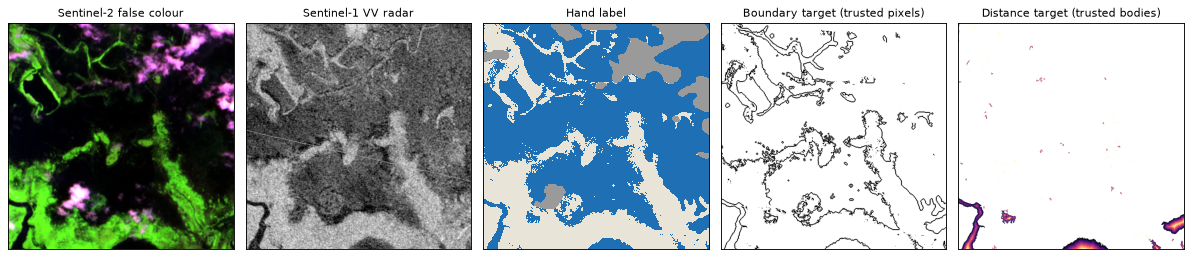

In [3]:
def targets_for(labels, margin=3):
    """(N, 5, H, W): extent, boundary, distance, then where boundary and distance can be trusted."""
    out = []
    for label in labels:
        ids = ndimage.label(label == 1)[0]
        near = ndimage.binary_dilation(label == 255, iterations=margin)
        boundary_ok = ~near
        distance_ok = (ids > 0) & ~np.isin(ids, np.unique(ids[near]))
        t = instance_targets(torch.from_numpy(ids), boundary_width=2)
        out.append(np.stack([t["extent"][0, 0].numpy(), t["boundary"][0, 0].numpy(),
                             t["distance"][0, 0].numpy(), boundary_ok, distance_ok]))
    return np.stack(out, dtype=np.float32)


fields = {split: targets_for(arrays[2]) for split, arrays in data.items()}


def false_colour(s2):
    rgb = s2[[12, 8, 3]].transpose(1, 2, 0)  # B12, B8A, B4: water is nearly black
    low, high = np.percentile(rgb, (2, 98), axis=(0, 1))
    return np.clip((rgb - low) / np.maximum(high - low, 1e-6), 0, 1)


def radar(s1):
    return np.clip((s1[0] + 25) / 25, 0, 1)  # VV between -25 and 0 dB: smooth water is dark


LABEL_COLOURS = ListedColormap(["#e8e4d8", "#1f6fb4", "#9a9a9a"])  # land, water, no data
i = int(np.argmax([(label == 1).mean() for label in data["bolivia"][2]]))
s2, s1, y = (a[i] for a in data["bolivia"])
panels = [("Sentinel-2 false colour", false_colour(s2), {}),
          ("Sentinel-1 VV radar", radar(s1), {"cmap": "gray"}),
          ("Hand label", np.where(y == 255, 2, y),
           {"cmap": LABEL_COLOURS, "vmin": 0, "vmax": 2, "interpolation": "nearest"}),
          ("Boundary target (trusted pixels)",
           np.ma.masked_where(fields["bolivia"][i, 3] == 0, fields["bolivia"][i, 1]),
           {"cmap": "gray_r"}),
          ("Distance target (trusted bodies)",
           np.ma.masked_where(fields["bolivia"][i, 4] == 0, fields["bolivia"][i, 2]),
           {"cmap": "magma"})]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, (title, image, kw) in zip(axes, panels):
    ax.imshow(image, **kw)
    ax.set(title=title, xticks=[], yticks=[])
fig.tight_layout()

## Build the model

Each sensor gets its own encoder, and a learned gate combines their features at every stride. The
first input sets the output grid. Both sensors here share a 10 m grid. For a coarser input add
`"alignment": "same_extent"` to its config, as in
[`examples/03_multi_modal.py`](https://github.com/DPIRD-DMA/ManySeg/blob/main/examples/03_multi_modal.py).

In [4]:
PRETRAINED = not SMOKE  # ImageNet weights, downloaded once (a real run should keep this)
model = create_model(
    pretrained=PRETRAINED,
    inputs={
        "s2": {"in_channels": 13, "backbone": "resnet18"},
        "s1": {"in_channels": 2, "backbone": "resnet18"},
    },
    fusion={"type": "intermediate", "op": "gated"},
    decoder="unet",
    heads={
        **instance_heads(),  # extent, boundary, distance: one value per pixel
        "water_share": {"type": "regression", "out_channels": 1, "scope": "image"},
    },
).to(device)

sample = {"s2": torch.zeros(1, 13, 256, 256, device=device),
          "s1": torch.zeros(1, 2, 256, 256, device=device)}
print(model.describe(sample))

DenseModel
  params: 25.57M
  FLOPs: 16.61G for this sample
  returns: dict of 4 heads
  fusion: intermediate
  input: padded per input to each encoder's divisor
  params by stage: encoders 22.38M, fusion 36.87k, decoders 3.15M, heads 948
inputs
  s2: raster, 13 ch
      alignment: same_grid
      primary: yes
      shape sample: 1x13x256x256
  s1: raster, 2 ch
      alignment: same_grid
      shape sample: 1x2x256x256
encoders
  s2: resnet18 (pretrained)  [11.21M params, 5.77G FLOPs]
      stem: 13 ch, 'repeat' weights from 3 ch (ch i starts from pretrained filter i % 3, x3/13)
      levels: 64@/2, 64@/4, 128@/8, 256@/16, 512@/32
      divisor: 32
      sharing: independent
      <- input: s2
      shape padded in: 1x13x256x256
      shape out: 1x64x128x128, 1x64x64x64, 1x128x32x32, 1x256x16x16, 1x512x8x8
  s1: resnet18 (pretrained)  [11.17M params, 4.63G FLOPs]
      stem: 2 ch, 'repeat' weights from 3 ch (ch i starts from pretrained filter i % 3, x3/2)
      levels: 64@/2, 64@/4, 12

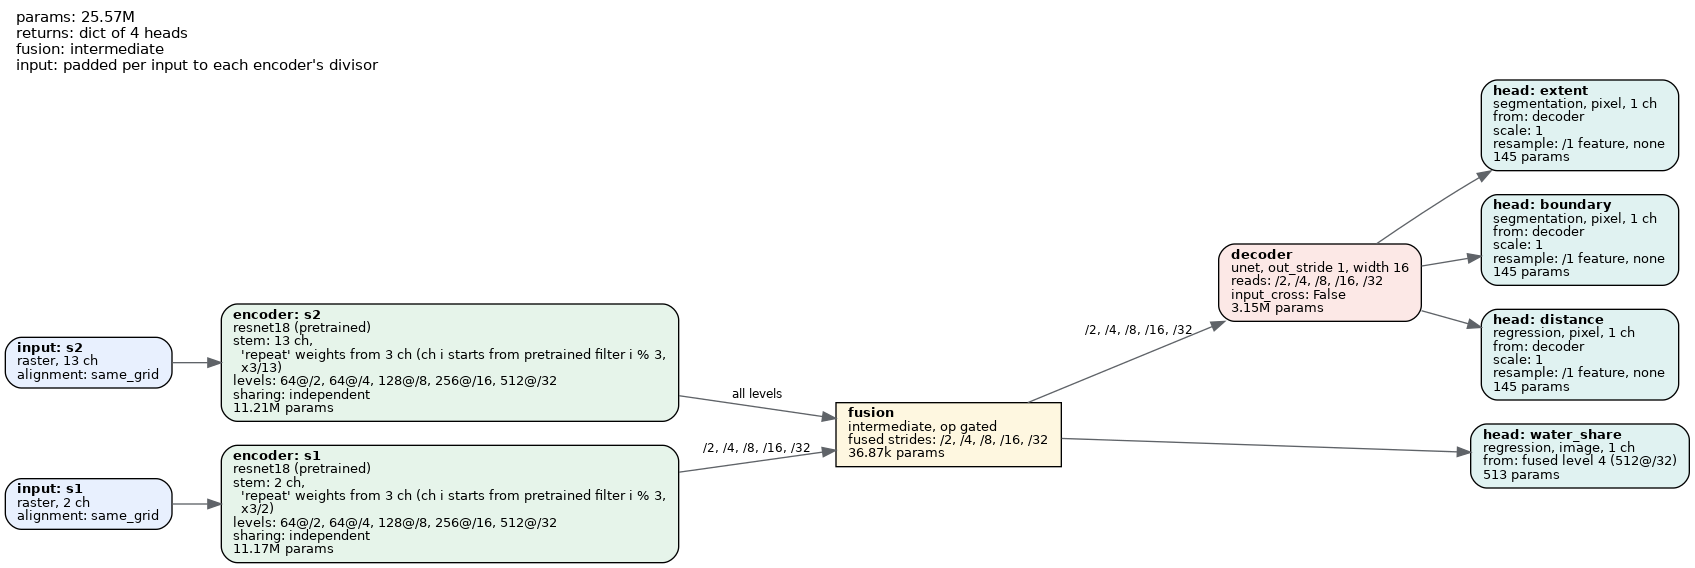

In [5]:
if shutil.which("dot"):
    with TemporaryDirectory() as tmp:
        png = Path(tmp) / "model.png"
        render_dot(model.describe(format="dot"), str(png))
        display(Image(filename=png, width=700))
else:
    print("Graphviz 'dot' is not installed, so there is no diagram.")

## Train

`multi_head_loss` takes one loss per head and adds them up. Each loss here closes over its own mask
from the previous step, so untrustworthy pixels cost nothing.

epoch  10: extent 0.937, boundary 1.175, distance 0.206, water_share 0.071


epoch  20: extent 0.735, boundary 0.955, distance 0.216, water_share 0.054


epoch  30: extent 0.619, boundary 0.845, distance 0.197, water_share 0.043


epoch  40: extent 0.621, boundary 0.834, distance 0.188, water_share 0.037


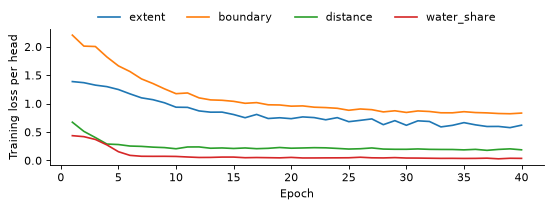

In [6]:
def normalise(key, array):
    mean, std = stats[key]
    return (array - mean) / std


class Crops(Dataset):
    def __init__(self, s2, s1, labels, fields, size=256):
        self.s2, self.s1 = normalise("s2", s2), normalise("s1", s1)
        self.labels, self.fields, self.size = labels, fields, size

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        top, left = np.random.randint(0, self.labels.shape[-1] - self.size + 1, 2)
        window = (..., slice(top, top + self.size), slice(left, left + self.size))
        arrays = [a[i][window] for a in (self.s2, self.s1, self.labels, self.fields)]
        if np.random.rand() < 0.5:
            arrays = [a[..., ::-1] for a in arrays]
        if np.random.rand() < 0.5:
            arrays = [a[..., ::-1, :] for a in arrays]
        return tuple(torch.from_numpy(a.copy()) for a in arrays)


def batch_loss(out, labels, field):
    valid = (labels != 255)[:, None].float()
    water = (labels == 1).float()
    share = (water * valid[:, 0]).sum((1, 2)) / valid.sum((1, 2, 3)).clamp(min=1)
    targets = {"extent": field[:, :1], "boundary": field[:, 1:2], "distance": field[:, 2:3],
               "water_share": share[:, None]}
    losses = {
        "extent": lambda o, t: dice_bce(o, t, mask=valid),
        "boundary": lambda o, t: dice_bce(o, t, mask=field[:, 3:4]),
        "distance": lambda o, t: masked_regression(o, t, mask=field[:, 4:5]),
        "water_share": lambda o, t: F.l1_loss(o.sigmoid(), t),
    }
    return multi_head_loss(out, targets, losses)


np.random.seed(0)
train = Crops(*data["train"], fields["train"])
loader = DataLoader(train, batch_size=2 if SMOKE else 8, shuffle=True, drop_last=not SMOKE)
optimiser = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
schedule = torch.optim.lr_scheduler.OneCycleLR(optimiser, max_lr=1e-3,
                                               total_steps=EPOCHS * len(loader))
history = {head: [] for head in ("extent", "boundary", "distance", "water_share")}
model.train()
for epoch in range(EPOCHS):
    totals = dict.fromkeys(history, 0.0)
    for s2, s1, labels, field in loader:
        labels, field = labels.to(device), field.to(device)
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            out = model({"s2": s2.to(device), "s1": s1.to(device)})
            loss, parts = batch_loss(out, labels, field)
        optimiser.zero_grad()
        loss.backward()
        optimiser.step()
        schedule.step()
        for head in totals:
            totals[head] += parts[head].item() / len(loader)
    for head in history:
        history[head].append(totals[head])
    if epoch % 10 == 9 or epoch == EPOCHS - 1:
        print(f"epoch {epoch + 1:3}: " + ", ".join(f"{k} {v:.3f}" for k, v in totals.items()))

fig, ax = plt.subplots(figsize=(7, 2.8))
for head, values in history.items():
    ax.plot(range(1, EPOCHS + 1), values, label=head, marker="o" if SMOKE else None)
ax.set(xlabel="Epoch", ylabel="Training loss per head")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, ncols=4, loc="upper center", bbox_to_anchor=(0.5, 1.2))
fig.tight_layout()

## See every output

`instances_from_outputs` runs outside the model. It combines the extent, boundary and distance
heads into one numbered map of water bodies, where each colour below is a separate body.

Some areas need care when you read these. The distance head only trains inside water, so we show
it only where the extent head says water. Where neither sensor has data, like the wedge in one of
these chips, the model's output means nothing, so we hide it. The clouds in the first column are
no-data in the labels, so nothing here scores the model under cloud, even though radar can see
through it.

water IoU on test: 0.734
water IoU on bolivia: 0.778


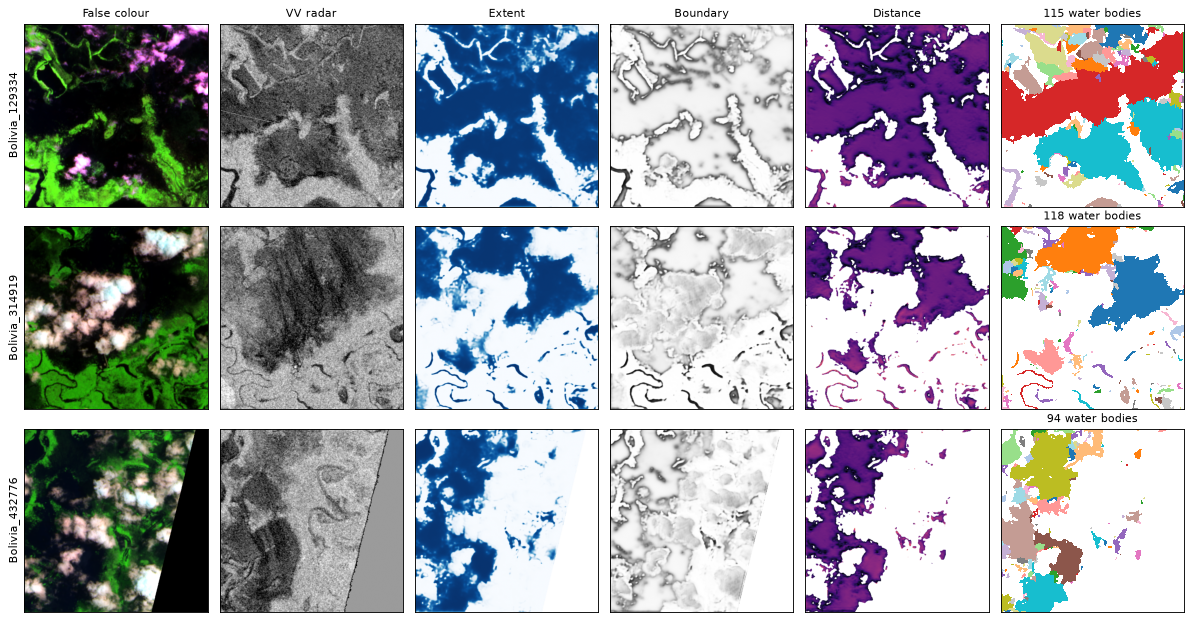

In [7]:
@torch.no_grad()
def predict(s2, s1, batch_size=4):
    model.eval()
    s2, s1 = torch.from_numpy(normalise("s2", s2)), torch.from_numpy(normalise("s1", s1))
    outs = []
    for a, b in zip(s2.split(batch_size), s1.split(batch_size)):
        with torch.autocast(device, dtype=torch.bfloat16, enabled=device == "cuda"):
            out = model({"s2": a.to(device), "s1": b.to(device)})
        outs.append({k: v.float().cpu() for k, v in out.items()})
    return {k: torch.cat([o[k] for o in outs]) for k in outs[0]}


def water_iou(pred, label):
    valid = label != 255
    inter = (pred & (label == 1) & valid).sum()
    union = ((pred | (label == 1)) & valid).sum()
    return inter / union if union else float("nan")


predictions = {split: predict(*data[split][:2]) for split in ("test", "bolivia")}
for split, out in predictions.items():
    water = out["extent"][:, 0].sigmoid().numpy() > 0.5
    print(f"water IoU on {split}: {water_iou(water, data[split][2]):.3f}")

out = predictions["bolivia"]
bodies = instances_from_outputs(out["extent"], out["boundary"], out["distance"], logits=True,
                                min_seed=8, min_size=16).numpy()
s2, s1, labels = data["bolivia"]
order = np.argsort([-(label == 1).mean() for label in labels])[:3]
fig, axes = plt.subplots(len(order), 6, figsize=(15, 2.6 * len(order)), squeeze=False)
for row, i in zip(axes, order):
    no_data = ~s2[i].any(0)  # zero in every band: outside the satellite's swath
    extent = out["extent"][i, 0].sigmoid().numpy()
    row[0].imshow(false_colour(s2[i]))
    row[1].imshow(radar(s1[i]), cmap="gray")
    row[2].imshow(np.ma.masked_where(no_data, extent), cmap="Blues", vmin=0, vmax=1)
    row[3].imshow(np.ma.masked_where(no_data, out["boundary"][i, 0].sigmoid().numpy()),
                  cmap="gray_r", vmin=0, vmax=1)
    row[4].imshow(np.ma.masked_where(no_data | (extent < 0.5), out["distance"][i, 0].numpy()),
                  cmap="magma", vmin=0, vmax=1)
    shown = np.where(no_data, 0, bodies[i])
    row[5].imshow(np.ma.masked_equal(shown, 0) % 20, cmap="tab20", vmin=0, vmax=19,
                  interpolation="nearest")
    row[5].set_title(f"{len(np.unique(shown)) - 1} water bodies")
    row[0].set_ylabel(names["bolivia"][i])
for ax, title in zip(axes[0], ("False colour", "VV radar", "Extent", "Boundary", "Distance")):
    ax.set_title(title)
for ax in axes.flat:
    ax.set(xticks=[], yticks=[])
fig.tight_layout()

## The image-level head

The fourth head has no decoder. It reads the fused encoder features and returns one number per
chip, in this case the share of valid pixels under water. Points on the grey line are perfect.

training chips over half water: 7 of 120


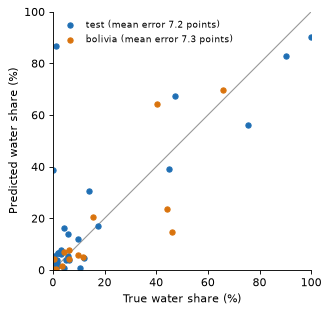

In [8]:
y = data["train"][2]
train_share = (y == 1).sum((1, 2)) / (y != 255).sum((1, 2)).clip(min=1)
print(f"training chips over half water: {(train_share > 0.5).sum()} of {len(y)}")

fig, ax = plt.subplots(figsize=(4.2, 4.2))
for split, colour in (("test", "#1f6fb4"), ("bolivia", "#d9730d")):
    y = data[split][2]
    valid = (y != 255).sum((1, 2)).clip(min=1)
    truth = ((y == 1).sum((1, 2)) / valid) * 100
    guess = predictions[split]["water_share"][:, 0].sigmoid().numpy() * 100
    error = np.abs(truth - guess).mean()
    ax.scatter(truth, guess, s=22, c=colour, label=f"{split} (mean error {error:.1f} points)")
ax.plot([0, 100], [0, 100], c="#999999", lw=1, zorder=0)
ax.set(xlabel="True water share (%)", ylabel="Predicted water share (%)", xlim=(0, 100),
       ylim=(0, 100), aspect="equal")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left", fontsize=8)
fig.tight_layout()

Look at the right of this plot. The head does worst on chips that are mostly water, and the count
printed above shows how few training chips look like that. Check a head like this across its whole
range before you trust an average error.

## Does radar help here?

This notebook shows how to wire two sensors together. It doesn't show that you should. In this
run the model scored no better than the first notebook's Sentinel-2 model, though that comparison
isn't fair, because this one has a smaller backbone and splits its training across four outputs.
The fair comparison is [E005](https://github.com/DPIRD-DMA/ManySeg/tree/main/experiments/E005_fusion_sen1floods11), which found no
fusion method on this dataset that beat Sentinel-2 alone or simply stacking the bands. Radar may
still pay off where clouds hide most of your images, but we haven't tested that, so try it on your
own data before you pay for a second encoder.

## Where to go next

* Add metadata such as day of year through FiLM, as in
  [`examples/03_multi_modal.py`](https://github.com/DPIRD-DMA/ManySeg/blob/main/examples/03_multi_modal.py).
  On this dataset metadata can identify the flood event, so it needs splits by event.
* Turn the water bodies into polygons, as in
  [the next notebook](03_vector_footprints.ipynb).